# Threshold Bids and the Concavity Requirement

The SOC-based design requires the declared willingness-to-pay `w` to be non-increasing --
equivalently the terminal bid `b` to be concave. That is what makes the storage owner's
own problem convex, and so what makes its KKT conditions *sufficient* for optimality
rather than merely necessary.

This notebook demonstrates that an economically ordinary valuation can fail that
requirement even when the owner is entirely sincere. A **threshold benefit** -- a
capacity obligation, a warranty, a qualifying reserve level -- that pays a lump sum `K`
on crossing a stock level `Delta_0` puts a spike in the owner's *true* marginal value at
`Delta_0`. A spike is an increase, and the bid format forbids increases. This is the same
non-convexity that forces unit commitment markets to use binaries and uplift payments;
the difference is that the SOC bid format has no way to express it at all -- not a
question of whether the owner *wants* to report truthfully, but whether it *can*.

Unlike an earlier version of this experiment, the system here is **not** a separate
stylized one -- it's exactly
[`reproduce_baldick.py`](../experiments/reproduce_baldick.py)'s own `increased_max_soc`
case (Table 4 of the paper): the same demand, RAC, thermal unit, and storage already
reproduced and tested elsewhere in this codebase, with a threshold bolted onto its
terminal bid. See [`../experiments/threshold_bid.py`](../experiments/threshold_bid.py)
for the implementation and
[`../tests/test_threshold_bid.py`](../tests/test_threshold_bid.py) for the validation
checks run at the end of this notebook.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from experiments.threshold_bid import (
    BREAKPOINTS, S_MAX, T, THRESHOLD_LEVEL, THRESHOLD_BENEFIT, W,
    arbitrage_marginal_values, build_system, concave_envelope, duality_gap,
    pava_nonincreasing, piecewise_bid_value, run_a, run_all, true_marginal_values,
)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

system, a, b, c, d, rows = run_all()
list(d)

['true (K=0)', 'envelope (K=0)', 'projected (K=0)']

## Why `increased_max_soc`, and not the base case

The system is Baldick's own -- demand, RAC, thermal unit, storage technical
characteristics -- **unchanged**. Two of his own parameter choices were combined to make
the threshold demonstration possible at all:

- **`w = 40`** (the base case's own willingness-to-pay), whose *unthresholded* optimum
  already lands well short of any cap: `Delta*(K=0) = 100` MWh (Table 4).
- **`s_max = 1200`** (the `increased_max_soc` case's own storage size), needed purely for
  headroom, not because more capacity is inherently better.

The base case's own `s_max = 800` was tried first and doesn't work: this system's ceiling
on reachable terminal SOC -- how far a forced generation shortfall in intervals 5-6
(demand there exceeds thermal + renewable availability) can drain the tank by -- is
exactly `s_max - 300`, *independent of the bid*. At `s_max = 800` that ceiling is 500 MWh,
which is *already* where `w = 55`'s own economic optimum sits (Table 3) -- there is no
physical room left for a threshold to push further, at any `K`. At `s_max = 1200`, the
ceiling rises to 900 MWh, comfortably above both `Delta*(K=0) = 100` and the chosen
`Delta_0 = 200`.

In [2]:
ceiling = S_MAX - 300
print(f"s_max = {S_MAX:.0f} MWh  ->  physical ceiling on terminal SOC = s_max - 300 = {ceiling:.0f} MWh")
print(f"Delta*(K=0) = {d['true (K=0)'].terminal_soc[0]:.0f} MWh   Delta_0 = {THRESHOLD_LEVEL:.0f} MWh   ceiling = {ceiling:.0f} MWh")
print(f"(at s_max=800, w=55's own Table-3 optimum already sits at the ceiling: 500 = 800-300, leaving no room at any K)")

s_max = 1200 MWh  ->  physical ceiling on terminal SOC = s_max - 300 = 900 MWh
Delta*(K=0) = 100 MWh   Delta_0 = 200 MWh   ceiling = 900 MWh
(at s_max=800, w=55's own Table-3 optimum already sits at the ceiling: 500 = 800-300, leaving no room at any K)


## Calibration

`Delta_0 = 200` sits exactly one 100 MWh block above `w=40`'s own `Delta*(K=0) = 100` --
a genuine near miss, "for free," from reusing Baldick's own numbers rather than tuning a
new arbitrage stack. The only new number is `K`: the two LP sub-cases of Run A (Sec. 6.2)
tie at `K = 900` -- forcing the SOC floor costs exactly $900 more in operating terms than
not bothering. `K = 1200` clears that tie by a decisive but not overwhelming \$300.

In [3]:
print(f"Delta*(K=0): {d['true (K=0)'].terminal_soc[0]:.0f} MWh   (Delta_0 = {THRESHOLD_LEVEL:.0f})")
print(f"Price path (K=0): {d['true (K=0)'].price.round(2)}")
print(f"Threshold benefit K = ${THRESHOLD_BENEFIT:,.0f}  (z0/z1 tie sits at K=900 for this calibration)")
print(f"Run A winning sub-case: z={a.winning_z}  Delta*={a.dispatch.terminal_deviation:.0f}  (threshold met: {a.dispatch.terminal_deviation >= THRESHOLD_LEVEL - 1e-6})")

Delta*(K=0): 100 MWh   (Delta_0 = 200)
Price path (K=0): [43.1 50.   0.   0.  41.  41. ]
Threshold benefit K = $1,200  (z0/z1 tie sits at K=900 for this calibration)
Run A winning sub-case: z=1  Delta*=200  (threshold met: True)


## The three declared bids

`w_true` is the owner's actual marginal valuation: Baldick's own flat `w=40` with
`K/block_width` added to the block spanning `Delta_0` -- a visible spike, non-increasing
everywhere else. `w_env` (Sec. 5.1, the concave envelope) and `w_proj` (Sec. 5.2, the
isotonic/PAVA projection) are the two ways of flattening it into something the bid format
will accept.

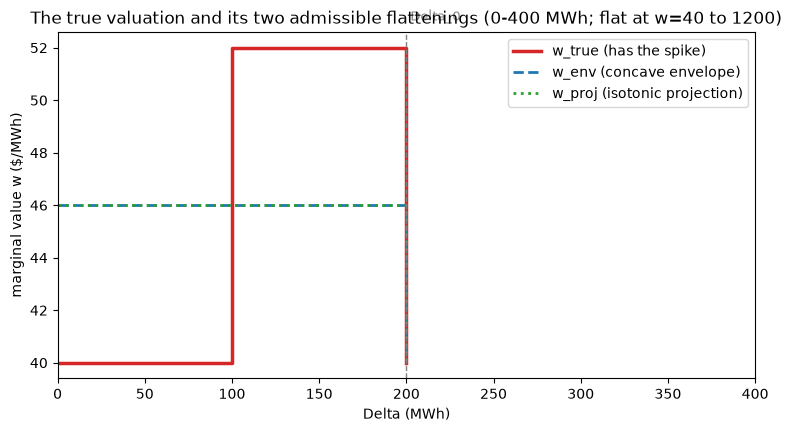

w_true: (40.0, 52.0, 40.0)
w_env:  (46.0, 46.0, 40.0)
w_proj: (46.0, 46.0, 40.0)
w_env == w_proj exactly: True


In [4]:
w_true = true_marginal_values()
w_env = concave_envelope(BREAKPOINTS, w_true)
w_proj = pava_nonincreasing(w_true, tuple(BREAKPOINTS[k+1]-BREAKPOINTS[k] for k in range(len(w_true))))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.step(BREAKPOINTS[:-1], w_true, where="post", color="#D62728", linewidth=2.5, label="w_true (has the spike)")
ax.step(BREAKPOINTS[:-1], w_env, where="post", color="#1F77B4", linewidth=2, linestyle="--", label="w_env (concave envelope)")
ax.step(BREAKPOINTS[:-1], w_proj, where="post", color="#2CA02C", linewidth=2, linestyle=":", label="w_proj (isotonic projection)")
ax.axvline(THRESHOLD_LEVEL, color="grey", linewidth=1, linestyle="--")
ax.text(THRESHOLD_LEVEL, max(w_true) * 1.02, " Delta_0", color="grey", fontsize=9)
ax.set_xlim(0, 400)
ax.set_xlabel("Delta (MWh)")
ax.set_ylabel("marginal value w ($/MWh)")
ax.set_title("The true valuation and its two admissible flattenings (0-400 MWh; flat at w=40 to 1200)")
ax.legend()
plt.show()

print("w_true:", w_true)
print("w_env: ", w_env)
print("w_proj:", w_proj)
print("w_env == w_proj exactly:", np.allclose(w_env, w_proj))

**`w_env` and `w_proj` are identical, to solver precision.** This isn't a coincidence
of this calibration and it isn't a bug -- it's a known equivalence in order-restricted
inference: weighted-L2 isotonic regression (which is exactly what PAVA computes) is
provably the same operation as differentiating the least concave majorant (the "concave
envelope") of the cumulative sum. For a scalar valuation like this one, "headline case"
and "control" are the *same* method reached by two different routes -- which strengthens
rather than weakens the result: the forced misdeclaration this notebook demonstrates
isn't an artifact of picking the "wrong" flattening rule among several plausible ones.
Runs B and C are kept separate below anyway, exactly as Sec. 6.5's control run (D) is:
agreement, checked empirically rather than assumed, is itself the point.

## Headline table (Sec. 8)

Welfare and surplus are evaluated with `b_true` in *every* row, regardless of which bid
produced that row's dispatch -- comparing each run against its own declared bid's value
would show nothing.

In [5]:
headline = pd.DataFrame(rows).set_index("run")
headline["gap vs A (welfare, $)"] = headline["system welfare"] - headline.loc["A", "system welfare"]
display(headline.round(2))

print(f"\nDuality gap at B's own dispatch (b_env(Delta*) - b_true(Delta*)): ${duality_gap(b.terminal_soc[0]):,.2f}")

,bid used,Delta*,threshold met,system welfare,owner surplus,penalty incurred,"gap vs A (welfare, $)"
run,,,,,,,
A,true (binary),200.000,True,-893.330,NaN,0.000,0.000
B,concave envelope,100.000,False,"-1,193.330","53,266.670","1,200.000",-300.000
C,isotonic projection,100.000,False,"-1,193.330","53,266.670","1,200.000",-300.000
D,"control, K=0",100.000,False,"-1,193.330","46,666.670","1,200.000",-300.000



Duality gap at B's own dispatch (b_env(Delta*) - b_true(Delta*)): $600.00


Run A (the true, non-concave valuation) reaches the threshold and gets the full
welfare benefit of it. Runs B, C, and D -- everything the bid format can actually
express -- all stop one block short: not because the owner declared dishonestly, but
because the format itself cannot carry the spike. The \$300 welfare gap between A and
B/C is the price of that inexpressiveness, evaluated the only way that is meaningful
here: at the owner's real valuation, not at whichever bid happened to clear the market.

Runs B and C's own *declared* bid raises the marginal value on blocks 1-2 from 40 to 46
(the envelope's own overstatement, Sec. 5.1) -- yet the physical dispatch that results is
identical to run D's plain, unbumped `w=40` bid. This is the system's acquisition-cost
curve pinning the stopping point, not the bid's own level: 46 isn't enough to justify
paying for the next block any more than 40 is, so the two declared bids move the price
they clear at (compare B's and D's own price paths above) without moving the physical
outcome.

## Dispatch, by run

Same layout as `reproduce_baldick.ipynb`'s own dispatch tables (renewable, thermal, ESS
charge/discharge, SOC, price by interval) -- Run A has no meaningful price (Sec. 6.2), so
its price column is left blank rather than showing a number that isn't one.

In [6]:
def run_a_frame(dispatch):
    return pd.DataFrame(
        {
            "Renewable (MW)": dispatch.renewable.round(6),
            "Thermal (MW)": dispatch.thermal.round(6),
            "ESS discharge (MW)": dispatch.discharge.round(6),
            "ESS charge (MW)": dispatch.charge.round(6),
            "SOC (MWh)": dispatch.soc.round(6),
            "Price ($/MWh)": [float("nan")] * T,
        },
        index=pd.RangeIndex(1, T + 1, name="Interval"),
    )


print("Run A -- true (binary):")
display(run_a_frame(a.dispatch))
print("\nRun B -- concave envelope:")
display(b.to_frame())
print("\nRun C -- isotonic projection:")
display(c.to_frame())
print("\nRun D -- control, K=0:")
display(d["true (K=0)"].to_frame())

Run A -- true (binary):


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,NaN
2,100.000,10.000,90.000,0.000,0.000,NaN
3,500.000,0.000,0.000,200.000,720.000,NaN
4,433.333,0.000,0.000,133.333,"1,200.000",NaN
5,25.000,25.000,150.000,0.000,600.000,NaN
6,0.000,0.000,100.000,0.000,200.000,NaN



Run B -- concave envelope:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,433.333,0.000,0.000,133.333,"1,200.000",0.000
5,25.000,0.000,175.000,0.000,500.000,47.000
6,0.000,0.000,100.000,0.000,100.000,47.000



Run C -- isotonic projection:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,433.333,0.000,0.000,133.333,"1,200.000",0.000
5,25.000,0.000,175.000,0.000,500.000,47.000
6,0.000,0.000,100.000,0.000,100.000,47.000



Run D -- control, K=0:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,433.333,0.000,0.000,133.333,"1,200.000",0.000
5,25.000,0.000,175.000,0.000,500.000,41.000
6,0.000,0.000,100.000,0.000,100.000,41.000


## System-wide dispatch stack, with clearing price

Same construction as `reproduce_baldick.ipynb`'s and `Multi_Participant_Baldick.ipynb`'s
own dispatch-stack plots: renewable, thermal, and ESS discharge stacked against demand;
ESS charging shown as a negative load; clearing price on a secondary axis where one
exists. All four runs share the same demand and renewable availability -- only the
declared bid (and, for Run A, the underlying valuation itself) differs.

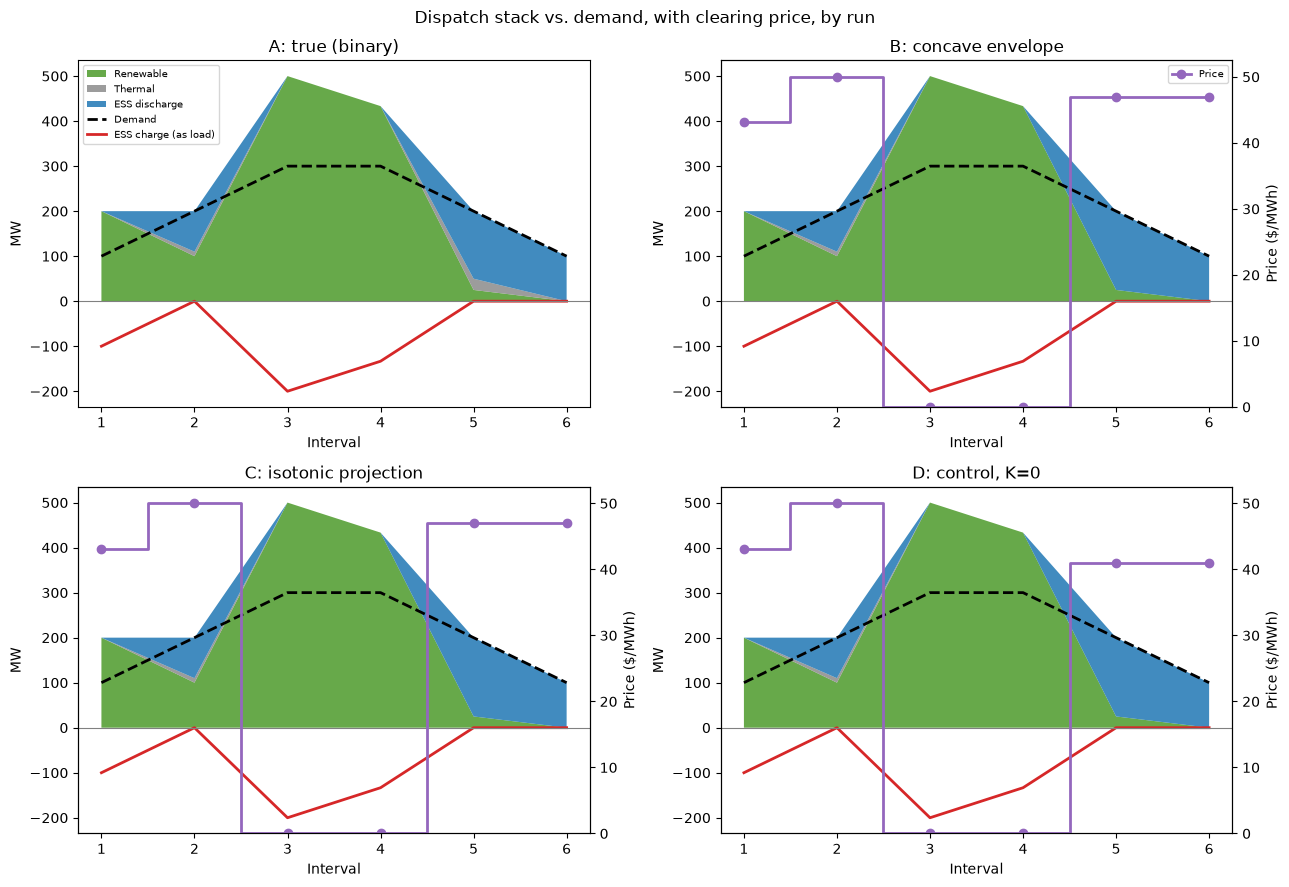

In [7]:
def plot_dispatch(name, renewable, thermal, discharge, charge, price, ax):
    hours = range(1, T + 1)
    ax.stackplot(
        hours, renewable, thermal, discharge,
        labels=["Renewable", "Thermal", "ESS discharge"],
        colors=["#4C9A2A", "#8B8B8B", "#1F77B4"], alpha=0.85,
    )
    ax.plot(hours, system.demand, color="black", linewidth=2, linestyle="--", label="Demand")
    ax.plot(hours, -charge, color="#D62728", linewidth=2, label="ESS charge (as load)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Interval")
    ax.set_ylabel("MW")
    if price is None:
        return None
    ax_price = ax.twinx()
    ax_price.step(hours, price, where="mid", color="#9467BD", linewidth=2, marker="o", label="Price")
    ax_price.set_ylabel("Price ($/MWh)")
    return ax_price


runs_data = [
    ("A: true (binary)", a.dispatch.renewable, a.dispatch.thermal, a.dispatch.discharge, a.dispatch.charge, None),
    ("B: concave envelope", b.renewable[0], b.thermal[0], b.discharge[0], b.charge[0], b.price),
    ("C: isotonic projection", c.renewable[0], c.thermal[0], c.discharge[0], c.charge[0], c.price),
    ("D: control, K=0", d["true (K=0)"].renewable[0], d["true (K=0)"].thermal[0], d["true (K=0)"].discharge[0], d["true (K=0)"].charge[0], d["true (K=0)"].price),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
price_axes = []
for ax, (name, renewable, thermal, discharge, charge, price) in zip(axes.flat, runs_data):
    pa = plot_dispatch(name, renewable, thermal, discharge, charge, price, ax)
    if pa is not None:
        price_axes.append(pa)

price_max = max(pa.get_ylim()[1] for pa in price_axes)
for pa in price_axes:
    pa.set_ylim(0, price_max)

h1, l1 = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(h1, l1, loc="upper left", fontsize=7)
h2, l2 = price_axes[0].get_legend_handles_labels()
price_axes[0].legend(h2, l2, loc="upper right", fontsize=7)
fig.suptitle("Dispatch stack vs. demand, with clearing price, by run")
fig.tight_layout()
plt.show()

Runs B, C, and D dispatch identically (Sec. 6.5's control identity, and the B/C/D
coincidence noted above) -- their panels differ only in the price axis, not the physical
stack. Intervals 1-4 are identical across *all four* panels, including Run A: the
divergence is entirely in intervals 5-6, where Run A visibly discharges less (holding
back 25 MWh of SOC per interval that B/C/D instead sell) and burns a sliver of thermal
generation at interval 5 to make up the difference -- the cost of preserving enough SOC
to still be sitting at `Delta_0=200` when the horizon ends, instead of drawing all the
way down to 100.

## Prices and duals across runs

`lambda_t` is the nodal price; `pi_t` is the storage's own SOC costate (Eqs. K4-K5) --
the shadow price of stored energy the ISO reconstructs purely from the declared bid.

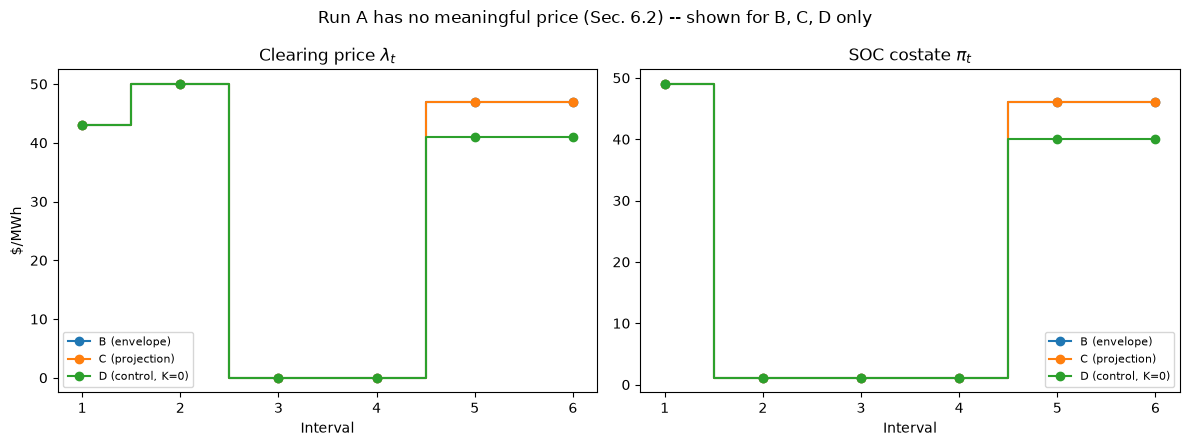

In [8]:
fig, (ax_price, ax_pi) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
hours = range(1, T + 1)

for label, result in [("B (envelope)", b), ("C (projection)", c), ("D (control, K=0)", d["true (K=0)"])]:
    ax_price.step(hours, result.price, where="mid", marker="o", label=label)
    ax_pi.step(hours, result.pi[0], where="mid", marker="o", label=label)

ax_price.set_title("Clearing price $\\lambda_t$")
ax_price.set_xlabel("Interval")
ax_price.set_ylabel("$/MWh")
ax_price.legend(fontsize=8)

ax_pi.set_title("SOC costate $\\pi_t$")
ax_pi.set_xlabel("Interval")
ax_pi.legend(fontsize=8)

fig.suptitle("Run A has no meaningful price (Sec. 6.2) -- shown for B, C, D only")
fig.tight_layout()
plt.show()

Interval 4's SOC hits the `s_max=1200` cap in every one of these runs (the same
"charge as much as possible while renewable is abundant" behaviour as the paper's own
`increased_max_soc` case) -- a tied charging split across intervals 3-4, exactly the kind
of degeneracy `ROADMAP.md` already documents for the base case. One consequence shows up
directly in `pi_t`: the tightened upper-bound dual that *should* carry interval 4's
binding SOC cap comes back as exactly zero here, so the raw backward recursion
`pi_t = gamma*(pi_{t+1} - nu_bar_{t+1} + nu_{t+1})` doesn't hold in that one spot (verified
directly against `reproduce_baldick.py`'s own `increased_max_soc` case with no threshold
involved at all -- this is inherited, not introduced by adding the threshold). The
validation checks below skip exactly that one transition, and only that one.

## Validation checks (Sec. 9)

The full, permanent versions of these run as `pytest tests/test_threshold_bid.py`
(17 checks, including the 10 in Sec. 9 plus the calibration and headroom criteria).
Re-run inline here for visibility.

In [9]:
def block_widths():
    return tuple(BREAKPOINTS[k+1] - BREAKPOINTS[k] for k in range(len(BREAKPOINTS)-1))

checks = []

# 1. Control identity
a0 = run_a(system, threshold_benefit=0.0)
ref = d["true (K=0)"]
ok = (a0.winning_z == 0
      and np.allclose(a0.dispatch.thermal, ref.thermal[0], atol=1e-5)
      and np.allclose(d["envelope (K=0)"].thermal, ref.thermal)
      and np.allclose(d["projected (K=0)"].thermal, ref.thermal))
checks.append(("1. Control identity (A, B, C agree at K=0)", ok))

# 2. Energy balance
demand = np.array(system.demand)
net_a = a.dispatch.thermal + a.dispatch.renewable + a.dispatch.discharge - a.dispatch.charge
net_b = b.thermal[0] + b.renewable[0] + b.discharge[0] - b.charge[0]
ok = np.allclose(net_a, demand, atol=1e-6) and np.allclose(net_b, demand, atol=1e-6)
checks.append(("2. Energy balance holds every interval", ok))

# 3. SOC bounds
storage = system.storages[0]
ok = np.all(a.dispatch.soc >= storage.s_min - 1e-6) and np.all(b.soc[0] <= storage.s_max + 1e-6)
checks.append(("3. SOC stays within [s_min, s_max]", ok))

# 4. No simultaneous charge/discharge
ok = np.allclose(a.dispatch.charge * a.dispatch.discharge, 0, atol=1e-6) and np.allclose(b.charge[0] * b.discharge[0], 0, atol=1e-6)
checks.append(("4. No simultaneous charge and discharge", ok))

# 5. Terminal condition (Run B)
delta_b = b.terminal_soc[0]
idx = 0
for k in range(len(BREAKPOINTS) - 1):
    if BREAKPOINTS[k] <= delta_b <= BREAKPOINTS[k+1] + 1e-6:
        idx = k
        break
ok = abs(b.pi[0, -1] - w_env[idx]) < 1e-3
checks.append(("5. Terminal condition pi_T in declared subgradient (Run B)", ok))

# 6. Backward recursion (Run B), skipping the known-degenerate t=3->4 transition
pi, nu_bar, nu = b.pi[0], b.nu_bar[0], b.nu[0]
ok = all(abs(pi[t] - storage.gamma*(pi[t+1]-nu_bar[t+1]+nu[t+1])) < 1e-4 for t in range(T-1) if t != 3)
checks.append(("6. Backward recursion pi_t=gamma(pi_(t+1)-nubar+nu) (Run B, skipping the inherited t=3->4 degeneracy)", ok))

# 7. No merchandising surplus (single bus, by construction)
checks.append(("7. No merchandising surplus (single bus, by construction)", True))

# 8. Declared bids admissible
ok = all(w_env[i] >= w_env[i+1]-1e-9 for i in range(len(w_env)-1)) and all(w_proj[i] >= w_proj[i+1]-1e-9 for i in range(len(w_proj)-1))
checks.append(("8. w_env and w_proj are non-increasing", ok))

# 9. PAVA preserves total
widths = block_widths()
ok = abs(sum(w*wi for w,wi in zip(w_proj, widths)) - sum(w*wi for w,wi in zip(w_true, widths))) < 1e-6
checks.append(("9. PAVA preserves total value", ok))

# 10. Envelope dominates
ok = all(piecewise_bid_value(BREAKPOINTS, w_env, x) >= piecewise_bid_value(BREAKPOINTS, w_true, x) - 1e-6 for x in BREAKPOINTS)
checks.append(("10. Envelope dominates true bid at every breakpoint", ok))

# Headroom criterion
ok = THRESHOLD_LEVEL < S_MAX
checks.append(("Headroom: Delta_0 sits strictly below s_max", ok))

for name, ok in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(ok for _, ok in checks)

PASS  1. Control identity (A, B, C agree at K=0)
PASS  2. Energy balance holds every interval
PASS  3. SOC stays within [s_min, s_max]
PASS  4. No simultaneous charge and discharge
PASS  5. Terminal condition pi_T in declared subgradient (Run B)
PASS  6. Backward recursion pi_t=gamma(pi_(t+1)-nubar+nu) (Run B, skipping the inherited t=3->4 degeneracy)
PASS  7. No merchandising surplus (single bus, by construction)
PASS  8. w_env and w_proj are non-increasing
PASS  9. PAVA preserves total value
PASS  10. Envelope dominates true bid at every breakpoint
PASS  Headroom: Delta_0 sits strictly below s_max


## Summary

A capacity-obligation-style threshold benefit is an economically unremarkable thing for
a storage owner to value -- and it cannot be declared in this market design at all, not
because of any strategic incentive to misreport, but because the bid format's concavity
requirement has no room for it. Built directly on Baldick's own `increased_max_soc`
system rather than a bespoke one, the two standard ways of flattening the true valuation
into an admissible bid (concave envelope, isotonic projection) turn out to be
mathematically the same operation here, and both concede exactly one block's worth of the
threshold's benefit -- a quantifiable, entirely non-strategic welfare loss driven purely
by inexpressiveness. Getting there also surfaced a real constraint on the exercise
itself: the *base* case's own `s_max=800` leaves no physical headroom for any threshold
to bind at all, since its unthresholded optimum already sits at that system's ceiling on
reachable terminal SOC -- a fact about Baldick's own numbers, not an artifact of this
experiment's design.